# Experiment 6 — Linear Regression and Diagnostics (House Price Dataset)

**Covers:** Multiple linear regression (OLS), correlation heatmap, coefficient table, R², adjusted R², MSE, RMSE, MAE, actual vs predicted, VIF, residual plots, Cook's distance and CSV export.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** OLS → Metrics → VIF → Residuals → Cook's Distance → Summary.

Target: `median_house_value`. The size columns (rooms, bedrooms, households, population) are deliberately kept to show multicollinearity in the VIF table.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("housing.csv")

## 1. Select data

       median_house_value  median_income  housing_median_age   total_rooms  \
count        20433.000000   20433.000000        20433.000000  20433.000000   
mean        206864.413155       3.871162           28.633094   2636.504233   
std         115435.667099       1.899291           12.591805   2185.269567   
min          14999.000000       0.499900            1.000000      2.000000   
25%         119500.000000       2.563700           18.000000   1450.000000   
50%         179700.000000       3.536500           29.000000   2127.000000   
75%         264700.000000       4.744000           37.000000   3143.000000   
max         500001.000000      15.000100           52.000000  39320.000000   

       total_bedrooms    population    households  
count    20433.000000  20433.000000  20433.000000  
mean       537.870553   1424.946949    499.433465  
std        421.385070   1133.208490    382.299226  
min          1.000000      3.000000      1.000000  
25%        296.000000    787.000000  

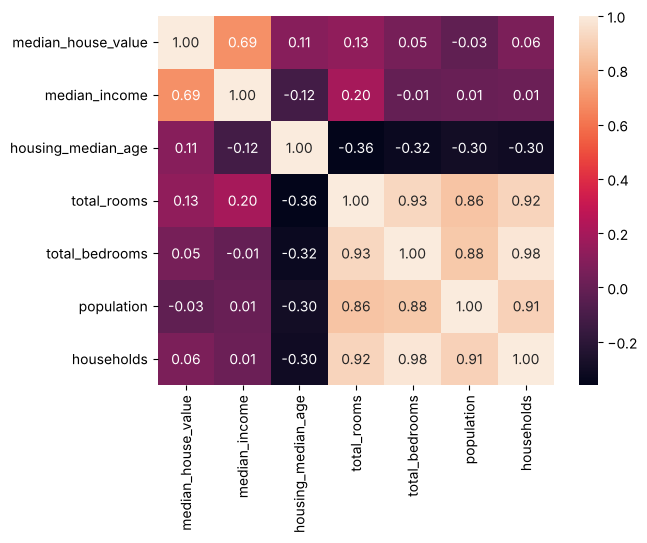

In [2]:
cols = ["median_income", "housing_median_age", "total_rooms",
        "total_bedrooms", "population", "households"]
data = df[["median_house_value"] + cols].dropna()
print(data.describe())

sns.heatmap(data.corr(), annot=True, fmt=".2f")
plt.show()

X = data[cols]
y = data["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 2. Linear regression (OLS)

In [3]:
model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())

coef = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t": model.tvalues,
    "p": model.pvalues
})
print(coef)

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.566
Model:                            OLS   Adj. R-squared:                  0.565
Method:                 Least Squares   F-statistic:                     3545.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:08:35   Log-Likelihood:            -2.0686e+05
No. Observations:               16346   AIC:                         4.137e+05
Df Residuals:                   16339   BIC:                         4.138e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -4.597e+04   2508

## 3. Predictions and evaluation

Train R2: 0.5655484565370036
Adjusted R2: 0.5653889174427642
Test R2: 0.5710755317440996
MSE: 5865619646.959242 RMSE: 76587.33346291175 MAE: 56642.49929909304


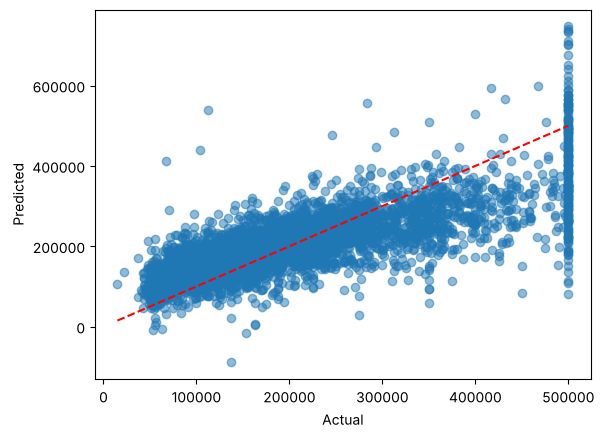

In [4]:
pred = model.predict(sm.add_constant(X_test))

mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("Train R2:", model.rsquared)
print("Adjusted R2:", model.rsquared_adj)
print("Test R2:", r2)
print("MSE:", mse, "RMSE:", rmse, "MAE:", mae)

plt.scatter(y_test, pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

## 4. VIF (multicollinearity)
VIF > 5 → moderate, VIF > 10 → high multicollinearity.

              Feature        VIF
0       median_income   1.514759
1  housing_median_age   1.160058
2         total_rooms  11.694052
3      total_bedrooms  33.984784
4          population   5.963206
5          households  31.991851


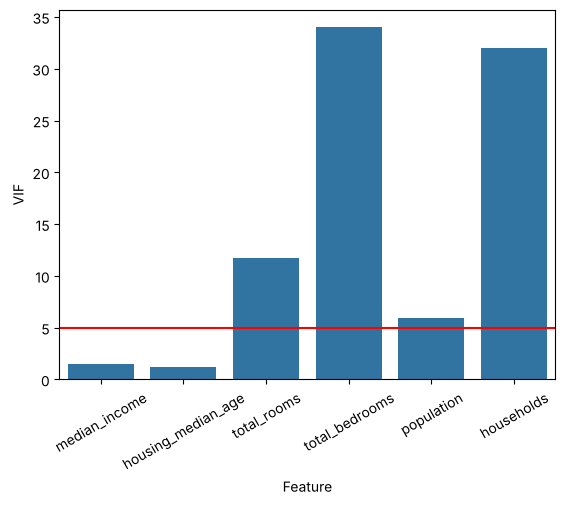

In [5]:
vif = pd.DataFrame({
    "Feature": cols,
    "VIF": [variance_inflation_factor(
        sm.add_constant(X_train).values, i + 1
    ) for i in range(len(cols))]
})
print(vif)

sns.barplot(data=vif, x="Feature", y="VIF")
plt.axhline(5, color="red")
plt.xticks(rotation=30)
plt.show()

## 5. Residual analysis

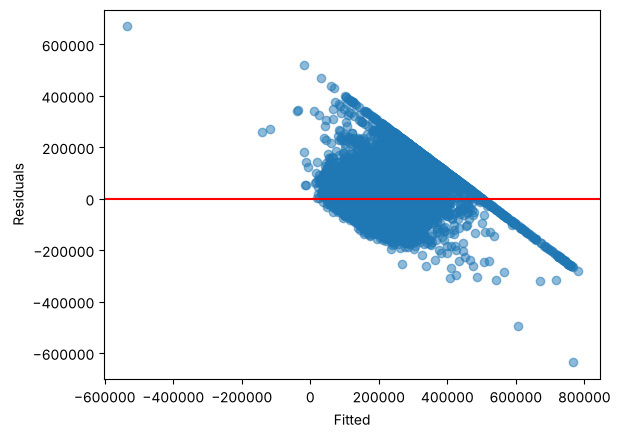

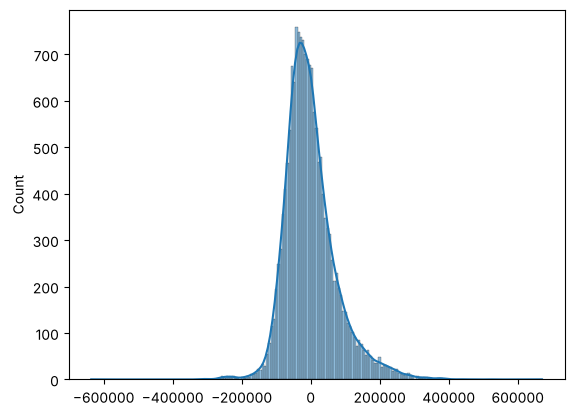

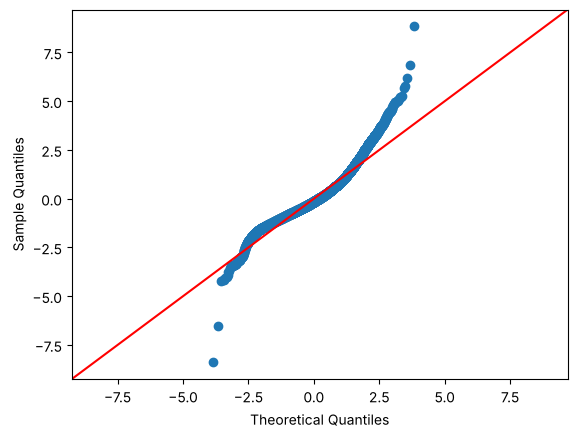

In [6]:
res = model.resid

plt.scatter(model.fittedvalues, res, alpha=0.5)
plt.axhline(0, color="red")
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.show()

sns.histplot(res, kde=True)
plt.show()

sm.qqplot(res, line="45", fit=True)
plt.show()

## 6. Cook's distance (influential points)
Rule of thumb: Cook's D > 4/n is influential.

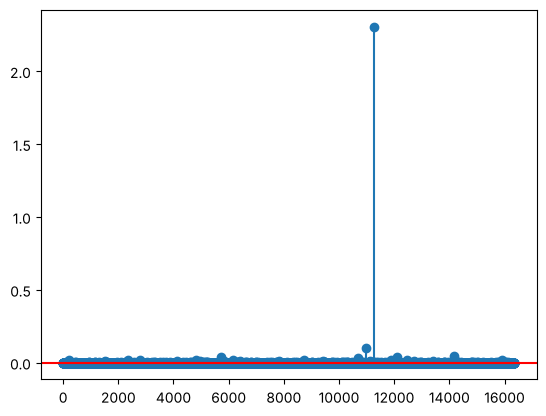

         Actual         Fitted       Residual  Std Residual   Cooks D
15360  134400.0 -535977.559629  670377.559629      9.583387  2.305770
9880   118800.0 -140505.800073  259305.800073      3.514173  0.099957
8985   500001.0  779924.321553 -279923.321553     -3.734684  0.048021
9172   154600.0 -116214.225003  270814.225003      3.607332  0.038673
18501  131300.0  767489.184211 -636189.184211     -8.402327  0.035816
16669  350000.0   25244.269741  324755.730259      4.307870  0.032703
3981   213900.0  474178.471577 -260278.471577     -3.451626  0.020040
9019   399200.0  202626.752559  196573.247441      2.616929  0.019217
922    451100.0  231937.254082  219162.745918      2.912187  0.019170
14505  280800.0  522094.693246 -241294.693246     -3.201156  0.018422


In [7]:
influence = OLSInfluence(model)
cooks = influence.cooks_distance[0]
limit = 4 / len(X_train)

plt.stem(range(len(cooks)), cooks)
plt.axhline(limit, color="red")
plt.show()

diagnostics = pd.DataFrame({
    "Actual": y_train,
    "Fitted": model.fittedvalues,
    "Residual": res,
    "Std Residual": influence.resid_studentized_internal,
    "Cooks D": cooks
})

print(diagnostics[diagnostics["Cooks D"] > limit].sort_values("Cooks D", ascending=False).head(10))

## 7. Summary and save

In [8]:
summary = pd.DataFrame({
    "Metric": ["Train R2", "Adjusted R2", "Test R2",
               "MSE", "RMSE", "MAE", "Max VIF", "Influential"],
    "Value": [model.rsquared, model.rsquared_adj, r2,
              mse, rmse, mae, vif["VIF"].max(), (cooks > limit).sum()]
})
print(summary)

coef.to_csv("coefficients.csv")
vif.to_csv("vif.csv", index=False)
diagnostics.to_csv("diagnostics.csv")
summary.to_csv("regression.csv", index=False)
print("Saved coefficients.csv, vif.csv, diagnostics.csv, regression.csv")

        Metric         Value
0     Train R2  5.655485e-01
1  Adjusted R2  5.653889e-01
2      Test R2  5.710755e-01
3          MSE  5.865620e+09
4         RMSE  7.658733e+04
5          MAE  5.664250e+04
6      Max VIF  3.398478e+01
7  Influential  8.230000e+02


Saved coefficients.csv, vif.csv, diagnostics.csv, regression.csv


## Result / Conclusion
- Model: `median_house_value` ~ income, house age and four size columns. Train R² = 0.566, **test R² = 0.571**, RMSE ≈ 76,587 USD.
- `median_income` is the strongest predictor: +1 unit (10,000 USD of income) adds about 47,700 USD to house value.
- **VIF shows strong multicollinearity:** `total_bedrooms` 34.0, `households` 32.0, `total_rooms` 11.7 – they all measure district size.
- Residuals form a diagonal stripe caused by the 500,001 price cap. 823 points exceed 4/n, and one district has Cook's D = 2.31 (> 1), a very influential point.